# 06 Baselines

This notebook scores simple secret scanners on the same test repositories as the models in `04_models.ipynb`, so the models have something to be compared with.

The first baseline is a regex only scanner of the kind many pre-commit tools use: it flags a line when a secret keyword sits next to an assignment, or when the line matches a known key format.

As in the other notebooks, outputs show counts and scores only, never `LineText` or `Value`.

## Setup

We load the cleaned rows with `load_data` from `src/features.py` and keep the rows from the test repositories in `repo_split.csv`, the split made in `03_preprocessing.ipynb`.

In [1]:
import re
import sys
from pathlib import Path

import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score

# The notebook runs from the notebooks folder so src and data sit one level up
sys.path.insert(0, str(Path("..") / "src"))
from features import load_data

PROCESSED = Path("..") / "data" / "processed"
pd.set_option("display.width", 200)

df = load_data()
split = pd.read_csv(PROCESSED / "repo_split.csv", dtype=str)
test_repos = set(split.loc[split["split"] == "test", "RepoId"])
test = df[df["RepoId"].isin(test_repos)].reset_index(drop=True)

print("test repositories:", len(test_repos))
print("test rows:", len(test))
print("label 1 share:", round(test["label"].mean() * 100, 2), "percent")
print(test["GroundTruth"].value_counts().reindex(["T", "F", "X"]).to_string())

test repositories: 67
test rows: 13235
label 1 share: 23.26 percent
GroundTruth
T    3078
F    8786
X    1371


## Regex baseline

The scanner looks at the line text only. A line is flagged when either kind of pattern matches:

- **Keyword next to an assignment**: a name containing password, secret, token, api key, access key, private key, auth or credential, followed by `=`, `:` or `:=`.
- **Known key formats**: a private key header, an AWS access key id, a GitHub token, a Slack token, a Google API key, a JSON Web Token, a Bearer token and a URL with a user and password in it.

These are written by hand and are not tuned on any data, so the baseline has nothing fitted on train or test.

In [2]:
KEYWORD_ASSIGN = re.compile(
    r"(?i)[a-z0-9_.\-]*(?:passw(?:or)?d|pwd|secret|token|api[_\-]?key|access[_\-]?key|private[_\-]?key|auth|credential)"
    r"[a-z0-9_.\-]*[\"']?\s*(?::=|=|:)"
)
KNOWN_FORMATS = {
    "private key header": r"-----BEGIN [A-Z ]*PRIVATE KEY",
    "aws access key id": r"\b(?:AKIA|ASIA)[0-9A-Z]{16}\b",
    "github token": r"\bgh[pousr]_[A-Za-z0-9]{36,}",
    "slack token": r"\bxox[abposr]-[A-Za-z0-9-]{10,}",
    "google api key": r"\bAIza[0-9A-Za-z_\-]{35}",
    "json web token": r"\beyJ[A-Za-z0-9_\-]{5,}\.[A-Za-z0-9_\-]{5,}\.[A-Za-z0-9_\-]{5,}",
    "bearer token": r"\b(?i:bearer)\s+[A-Za-z0-9._~+/\-]{16,}",
    "url with password": r"[a-z][a-z0-9+.\-]*://[^\s:/@]+:[^\s/@]+@",
}
KNOWN = re.compile("|".join(f"(?:{p})" for p in KNOWN_FORMATS.values()))

text = test["LineText"]
test["regex_keyword"] = text.map(lambda line: bool(KEYWORD_ASSIGN.search(line))).astype(int)
test["regex_format"] = text.map(lambda line: bool(KNOWN.search(line))).astype(int)
test["regex_flag"] = (test["regex_keyword"] | test["regex_format"]).astype(int)

for name, pattern in KNOWN_FORMATS.items():
    hits = text.str.contains(pattern, regex=True)
    print(f"{name}: {int(hits.sum())} rows, {round(test.loc[hits, 'label'].mean() * 100, 1) if hits.any() else '-'} percent real")

private key header: 134 rows, 82.8 percent real
aws access key id: 1 rows, 0.0 percent real
github token: 0 rows, - percent real
slack token: 2 rows, 100.0 percent real


google api key: 4 rows, 75.0 percent real
json web token: 52 rows, 96.2 percent real
bearer token: 20 rows, 100.0 percent real
url with password: 255 rows, 42.0 percent real


## Scores

Precision is the share of flagged lines that are real secrets, recall is the share of real secrets that get flagged, and F1 combines the two. We score the keyword rule and the format rule on their own and together.

In [3]:
def scores(name, flag):
    # Scores one baseline against the label on the test rows
    return {
        "baseline": name,
        "flagged rows": int(flag.sum()),
        "precision": round(precision_score(test["label"], flag, zero_division=0), 4),
        "recall": round(recall_score(test["label"], flag, zero_division=0), 4),
        "f1": round(f1_score(test["label"], flag, zero_division=0), 4),
    }


results = pd.DataFrame([
    scores("regex keyword next to assignment", test["regex_keyword"]),
    scores("regex known key formats", test["regex_format"]),
    scores("regex both", test["regex_flag"]),
    scores("flag every line", pd.Series(1, index=test.index)),
])
print(results.to_string(index=False))

                        baseline  flagged rows  precision  recall     f1
regex keyword next to assignment          6610     0.2434  0.5227 0.3322
         regex known key formats           464     0.6228  0.0939 0.1632
                      regex both          7024     0.2651  0.6049 0.3686
                 flag every line         13235     0.2326  1.0000 0.3774


## What the regex baseline flags by GroundTruth

The share of rows flagged in each GroundTruth group shows whether the scanner can tell F and X apart from real secrets at all.

In [4]:
by_gt = test.groupby("GroundTruth")[["regex_keyword", "regex_format", "regex_flag"]].mean().mul(100).round(1)
print(by_gt.reindex(["T", "F", "X"]).to_string())

             regex_keyword  regex_format  regex_flag
GroundTruth                                         
T                     52.3           9.4        60.5
F                     42.7           1.2        43.9
X                     90.9           4.9        95.5


## CredSweeper baseline

[CredSweeper](https://github.com/Samsung/CredSweeper) is an open source scanner from Samsung, the team that built CredData. It finds candidates with rules and then filters them with a small machine learning model.

**This comparison may not be fair to our models.** CredSweeper's machine learning filter was built by the same team and may have been trained on CredData, which could include the lines in our test set. A very high score from it would therefore not show that it generalizes better.

CredSweeper scans files, so each test line is written to its own temporary file, named by its `Id` and given its original extension so that CredSweeper applies the rules for that file type. A line counts as flagged when CredSweeper reports any finding in its file. We run it twice: with its machine learning filter (the default) and with rules only (`--ml_threshold 0`).

CredSweeper prints the values it finds, so printing is turned off with `--no-stdout` and only the saved JSON is read. The temporary files are deleted as soon as the scan ends.

In [5]:
import importlib.util
import json
import os
import subprocess
import tempfile


def run_credsweeper(rows, extra_args):
    # Writes each line to its own file, scans the folder and returns the set of flagged Ids
    with tempfile.TemporaryDirectory() as tmp:
        lines_dir = Path(tmp) / "lines"
        lines_dir.mkdir()
        for row_id, ext, line in zip(rows["Id"], rows["FileExt"], rows["LineText"]):
            name = f"{row_id}.{ext}" if ext else row_id
            (lines_dir / name).write_text(line + "\n", encoding="utf-8")
        out_path = Path(tmp) / "findings.json"
        command = [sys.executable, "-m", "credsweeper", "--path", str(lines_dir),
                   "--save-json", str(out_path), "--jobs", "4", "--no-stdout", "--no-color",
                   "--no-progress", "--log", "ERROR", *extra_args]
        # UTF 8 everywhere, because Windows cannot print some characters in the scanned lines
        env = {**os.environ, "PYTHONUTF8": "1", "PYTHONIOENCODING": "utf-8"}
        result = subprocess.run(command, capture_output=True, text=True, encoding="utf-8",
                                errors="replace", env=env)
        if result.returncode != 0:
            # Only the last line of the error is shown, which names the problem without the scanned text
            last_line = (result.stderr.strip().splitlines() or ["no error text"])[-1][:300]
            raise RuntimeError(f"CredSweeper stopped with exit code {result.returncode}: {last_line}")
        findings = json.loads(out_path.read_text(encoding="utf-8")) if out_path.exists() else []
    flagged = {Path(item["path"]).name.split(".")[0] for f in findings for item in f["line_data_list"]}
    return flagged, len(findings)


CREDSWEEPER_OK = importlib.util.find_spec("credsweeper") is not None
print("CredSweeper installed:", CREDSWEEPER_OK)
if CREDSWEEPER_OK:
    from importlib.metadata import version
    print("CredSweeper version:", version("credsweeper"))
    for column, args in [("credsweeper_ml", []), ("credsweeper_rules", ["--ml_threshold", "0"])]:
        flagged, n_findings = run_credsweeper(test, args)
        test[column] = test["Id"].isin(flagged).astype(int)
        print(f"{column}: {n_findings} findings on {int(test[column].sum())} rows")

CredSweeper installed: True
CredSweeper version: 1.19.6


credsweeper_ml: 4000 findings on 3101 rows


credsweeper_rules: 8349 findings on 6926 rows


## Comparison table

Every baseline is scored on the same 13,235 test rows. Aneeza adds the rows for the models from `04_models.ipynb` once their test scores are final.

In [6]:
rows = [
    scores("flag every line", pd.Series(1, index=test.index)),
    scores("regex keyword next to assignment", test["regex_keyword"]),
    scores("regex known key formats", test["regex_format"]),
    scores("regex both", test["regex_flag"]),
]
if CREDSWEEPER_OK:
    rows.append(scores("CredSweeper rules only", test["credsweeper_rules"]))
    rows.append(scores("CredSweeper with ML filter", test["credsweeper_ml"]))
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

flag_columns = ["regex_flag"] + (["credsweeper_rules", "credsweeper_ml"] if CREDSWEEPER_OK else [])
print()
print("percent of rows flagged, by GroundTruth")
print(test.groupby("GroundTruth")[flag_columns].mean().mul(100).round(1).reindex(["T", "F", "X"]).to_string())

# Only scores and flags by Id are saved, never the line text
test[["Id", "RepoId", "GroundTruth", "label"] + flag_columns].to_csv(PROCESSED / "baseline_flags.csv", index=False)
comparison.to_csv(PROCESSED / "baseline_scores.csv", index=False)
print()
print("saved baseline_flags.csv and baseline_scores.csv to data/processed")

                        baseline  flagged rows  precision  recall     f1
                 flag every line         13235     0.2326  1.0000 0.3774
regex keyword next to assignment          6610     0.2434  0.5227 0.3322
         regex known key formats           464     0.6228  0.0939 0.1632
                      regex both          7024     0.2651  0.6049 0.3686
          CredSweeper rules only          6926     0.4414  0.9932 0.6112
      CredSweeper with ML filter          3101     0.9787  0.9860 0.9824

percent of rows flagged, by GroundTruth
             regex_flag  credsweeper_rules  credsweeper_ml
GroundTruth                                               
T                  60.5               99.3            98.6
F                  43.9               41.3             0.7
X                  95.5               17.4             0.4

saved baseline_flags.csv and baseline_scores.csv to data/processed


## The models from 04_models

`04_models.ipynb` scores the nine models once on the same test rows and saves their scores to `data/processed/test_scores.csv` (Id and scores only, no text). Each model uses its own threshold, chosen from the out of fold predictions in `04_models`, never from the test set. The thresholds below are the full precision values from `04_models`, and the number of flagged rows is checked against the counts in `04_models`. With thresholds rounded to four decimals one model flagged one row more, which this check caught.

In [7]:
MODEL_THRESHOLDS = {
    "xgboost_no_value_empty": 0.41578322649002075, "xgboost_all": 0.41578322649002075,
    "random_forest_all": 0.4839527451585854, "random_forest_no_value_empty": 0.49241282779690143,
    "logreg_all": 0.6614400622139608, "logreg_no_value_empty": 0.6760090407010495,
    "random_forest_line_and_path": 0.17976091225904617, "xgboost_line_and_path": 0.2457287311553955,
    "logreg_line_and_path": 0.40274436375728856,
}
# Flagged rows on the test set as reported by 04_models
EXPECTED_FLAGGED = {
    "xgboost_no_value_empty": 3338, "xgboost_all": 3338, "random_forest_all": 3043,
    "random_forest_no_value_empty": 3002, "logreg_all": 3105, "logreg_no_value_empty": 3039,
    "random_forest_line_and_path": 7599, "xgboost_line_and_path": 7287, "logreg_line_and_path": 6714,
}

test_scores = pd.read_csv(PROCESSED / "test_scores.csv", dtype={"Id": str, "RepoId": str})
test = test.merge(test_scores[["Id", *MODEL_THRESHOLDS]], on="Id", how="left", validate="one_to_one")
print("test rows with a model score:", int(test["xgboost_no_value_empty"].notna().sum()), "of", len(test))

model_rows = []
for name, threshold in MODEL_THRESHOLDS.items():
    flag = (test[name] >= threshold).astype(int)
    row = scores(name, flag)
    row["matches 04_models"] = row["flagged rows"] == EXPECTED_FLAGGED[name]
    model_rows.append(row)
model_results = pd.DataFrame(model_rows)
print(model_results.to_string(index=False))

test rows with a model score: 13235 of 13235


                    baseline  flagged rows  precision  recall     f1  matches 04_models
      xgboost_no_value_empty          3338     0.8565  0.9288 0.8912               True
                 xgboost_all          3338     0.8565  0.9288 0.8912               True
           random_forest_all          3043     0.8889  0.8788 0.8838               True
random_forest_no_value_empty          3002     0.8944  0.8723 0.8832               True
                  logreg_all          3105     0.7900  0.7969 0.7935               True
       logreg_no_value_empty          3039     0.7930  0.7830 0.7880               True
 random_forest_line_and_path          7599     0.3785  0.9344 0.5387               True
       xgboost_line_and_path          7287     0.3796  0.8986 0.5337               True
        logreg_line_and_path          6714     0.3566  0.7778 0.4890               True


## The hook on the test lines

`src/hook.py` cannot see the annotated `Value`, so it finds the value with the rule agreed in `docs/DECISIONS.md`. Here we score the test lines with the saved model twice, using the same features, scaling, column order and threshold as the hook:

- **annotated value**: the features are built from the annotated `Value`, as in `04_models.ipynb`
- **hook value**: the features are built from the value the hook's rule finds in `LineText`, as the hook does on a real commit

Multi line rows (private keys) keep their annotated span, because the hook joins a key from its BEGIN line to its END line in the same way. `FilePath` is already in the CredData shape that the hook rebuilds from a real path.

The gap between the two rows shows how much the model loses when it runs as a real tool rather than on annotated data.

In [8]:
import joblib

from features import build_features
from hook import MODEL_PATH, extract_value, scale

bundle = joblib.load(MODEL_PATH)
print("model:", bundle["name"], "| features:", len(bundle["features"]), "| threshold:", bundle["threshold"])


def model_flags(rows):
    # Scores rows with the saved model exactly as src/hook.py does and returns scores and flags
    features = scale(build_features(rows))[bundle["features"]]
    proba = bundle["model"].predict_proba(features)[:, 1]
    return proba, (proba >= bundle["threshold"]).astype(int)


hook_rows = test.copy()
single_line = hook_rows["LineStart"] == hook_rows["LineEnd"]
hook_rows.loc[single_line, "Value"] = hook_rows.loc[single_line, "LineText"].map(extract_value)
print("single line test rows:", int(single_line.sum()))
same_value = hook_rows.loc[single_line, "Value"] == test.loc[single_line, "Value"]
has_value = test.loc[single_line, "Value"] != ""
print("hook value equals the annotated value, out of all single line test rows:",
      round(same_value.mean() * 100, 2), "percent")
print("hook value equals the annotated value, out of single line test rows that have an annotated value:",
      round(same_value[has_value].mean() * 100, 2), "percent of", int(has_value.sum()))

test["model_annotated_score"], test["model_annotated"] = model_flags(test)
test["model_hook_score"], test["model_hook"] = model_flags(hook_rows)

hook_results = pd.DataFrame([
    scores(f"{bundle['name']} with annotated value", test["model_annotated"]),
    scores(f"{bundle['name']} with hook value", test["model_hook"]),
])
print()
print(hook_results.to_string(index=False))
print()
print("percent of rows flagged, by GroundTruth")
print(test.groupby("GroundTruth")[["model_annotated", "model_hook"]].mean().mul(100).round(1).reindex(["T", "F", "X"]).to_string())

model: xgboost_no_value_empty | features: 38 | threshold: 0.41578322649002075
single line test rows: 13086
hook value equals the annotated value, out of all single line test rows: 24.68 percent
hook value equals the annotated value, out of single line test rows that have an annotated value: 49.93 percent of 6104



                                   baseline  flagged rows  precision  recall     f1
xgboost_no_value_empty with annotated value          3338     0.8565  0.9288 0.8912
     xgboost_no_value_empty with hook value          3175     0.6929  0.7147 0.7037

percent of rows flagged, by GroundTruth
             model_annotated  model_hook
GroundTruth                             
T                       92.9        71.5
F                        3.3         8.6
X                       13.7        16.2


## Full comparison

All baselines, the nine models from `04_models` and both ways of running the saved model, on the same 13,235 test rows.

In [9]:
full = pd.concat([comparison, model_results.drop(columns="matches 04_models"), hook_results], ignore_index=True)
print(full.to_string(index=False))

flag_columns = flag_columns + ["model_annotated", "model_hook"]
test[["Id", "RepoId", "GroundTruth", "label"] + flag_columns + ["model_annotated_score", "model_hook_score"]].to_csv(
    PROCESSED / "baseline_flags.csv", index=False)
full.to_csv(PROCESSED / "baseline_scores.csv", index=False)
print()
print("saved baseline_flags.csv and baseline_scores.csv to data/processed")

                                   baseline  flagged rows  precision  recall     f1
                            flag every line         13235     0.2326  1.0000 0.3774
           regex keyword next to assignment          6610     0.2434  0.5227 0.3322
                    regex known key formats           464     0.6228  0.0939 0.1632
                                 regex both          7024     0.2651  0.6049 0.3686
                     CredSweeper rules only          6926     0.4414  0.9932 0.6112
                 CredSweeper with ML filter          3101     0.9787  0.9860 0.9824
                     xgboost_no_value_empty          3338     0.8565  0.9288 0.8912
                                xgboost_all          3338     0.8565  0.9288 0.8912
                          random_forest_all          3043     0.8889  0.8788 0.8838
               random_forest_no_value_empty          3002     0.8944  0.8723 0.8832
                                 logreg_all          3105     0.7900  0.7969

## Comparison chart

F1 on the test rows for the baselines, the hook model and the hook as it runs on a real commit. The chart is saved to `images/12_model_comparison.png` for the README.

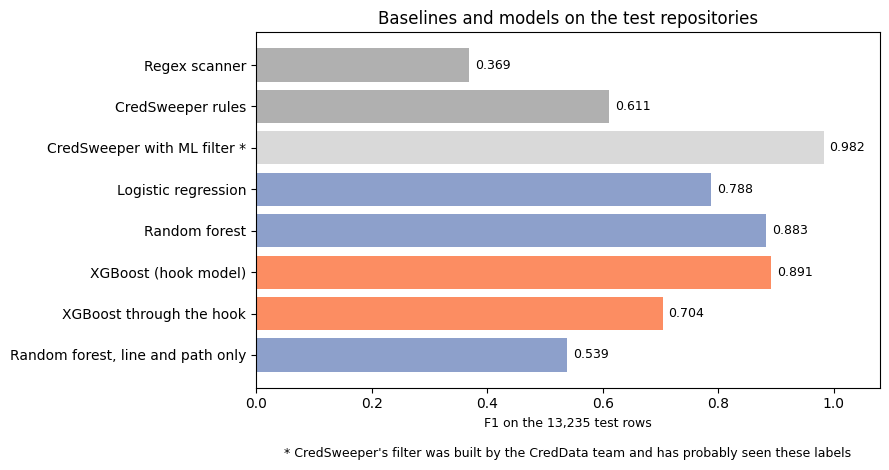

                                   precision  recall      f1
baseline                                                    
Regex scanner                         0.2651  0.6049  0.3686
CredSweeper rules                     0.4414  0.9932  0.6112
CredSweeper with ML filter *          0.9787  0.9860  0.9824
Logistic regression                   0.7930  0.7830  0.7880
Random forest                         0.8944  0.8723  0.8832
XGBoost (hook model)                  0.8565  0.9288  0.8912
XGBoost through the hook              0.6929  0.7147  0.7037
Random forest, line and path only     0.3785  0.9344  0.5387


In [10]:
import matplotlib.pyplot as plt

chart_rows = {
    "regex both": "Regex scanner",
    "CredSweeper rules only": "CredSweeper rules",
    "CredSweeper with ML filter": "CredSweeper with ML filter *",
    "logreg_no_value_empty": "Logistic regression",
    "random_forest_no_value_empty": "Random forest",
    "xgboost_no_value_empty": "XGBoost (hook model)",
    f"{bundle['name']} with hook value": "XGBoost through the hook",
    "random_forest_line_and_path": "Random forest, line and path only",
}
chart = full.set_index("baseline").loc[list(chart_rows), ["precision", "recall", "f1"]].rename(index=chart_rows)
colors = ["#b0b0b0", "#b0b0b0", "#d9d9d9", "#8da0cb", "#8da0cb", "#fc8d62", "#fc8d62", "#8da0cb"]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(chart.index[::-1], chart["f1"][::-1], color=colors[::-1])
for i, value in enumerate(chart["f1"][::-1]):
    ax.text(value + 0.01, i, f"{value:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1.08)
ax.set_xlabel("F1 on the 13,235 test rows\n\n* CredSweeper's filter was built by the CredData team and has probably seen these labels",
              fontsize=9)
ax.set_title("Baselines and models on the test repositories")
fig.tight_layout()
IMAGES = Path("..") / "images"
fig.savefig(IMAGES / "12_model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()
print(chart.round(4).to_string())